# NDT-Transformer on KITTI: experiments

Runtime -> Change runtime type -> **T4 GPU** (or better).

**One experiment = one NDT variant + one training run.** Set both in cell 1 and run every cell from top to bottom.
Every cell skips work that is already done, so the same order works for a new experiment, after a disconnect, or in a new session:

- **NDT variant**: the preprocessing + G parameters, independent of the sequence. Saved in `MyDrive/lpr/ndt/<variant>/` with its `config.json`, one cells tar and one stats file per sequence, and a preview picture. A variant with the same parameters is never built twice.
- **Run**: the training parameters. Saved in `MyDrive/lpr/runs/ndt/<run>/` with `config.json` (parameters, NDT variant, GPU, code version, status), `metrics.csv`, a checkpoint per epoch and the final evaluation. An unfinished run with the same parameters is resumed; finished runs are never overwritten.
- `MyDrive/lpr/runs_summary.csv`: one row per run (cell 8).
- BEVPlace++ has its own notebook (`02_bevplace_kitti.ipynb`) with the same layout: `MyDrive/lpr/bev/<variant>/`, `MyDrive/lpr/runs/bev/<run>/`.
- Section 9 evaluates a trained run on all sequences (cells built on Azure) and analyses the query headings.

Names are `<date>_<tag>_<hash>`: the hash is computed from the parameters.

## 1. Experiment settings

In [1]:
REPO_URL = "https://github.com/dov85/lidar-place-recognition"
DRIVE = "/content/drive/MyDrive/lpr"
SEQ = "00"

# NDT variant: only what differs from the defaults (src/lpr/experiments.py, NDT_DEFAULTS):
#   crop="square", half_size=40.0, ground="patchwork", k=2000, over=0.10, radius=0.8,
#   min_pts=5, knn=8, cov_eps=1e-3
NDT_TAG = ""          # name for a changed variant; empty = date + hash
NDT_PARAMS = dict()                 # e.g. dict(crop="circle", radius=1.0)

# Training run: only what differs from the defaults (TRAIN_DEFAULTS):
#   pos_thr=5.0, neg_thr=7.0, epochs=20, lr=1e-5, milestones=[9, 15], batch_queries=2,
#   positives=2, negatives=18, margin1=0.5, margin2=0.2, hard_neg_after_epoch=5, amp=True, seed=0,
#   cov_transform=False  (True: the T-Net also transforms the covariances, as in the paper)
RUN_TAG = ""          # name for a changed run; empty = date + hash
TRAIN_PARAMS = dict(cov_transform=True)               # e.g. dict(lr=5e-6, negatives=12)

KITTI = "/content/kitti"                       # raw scans + poses (temporary)
RAW_TAR = f"{DRIVE}/kitti_seq00_raw.tar"       # backup of the raw scans of sequence 00

## 2. Drive, GPU, code, poses

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys, json, subprocess, importlib
os.makedirs(DRIVE, exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv

url = REPO_URL
try:  # private repo: store a token in Colab Secrets as GITHUB_TOKEN
    from google.colab import userdata
    url = REPO_URL.replace("https://", f"https://{userdata.get('GITHUB_TOKEN')}@")
except Exception:
    pass
if not os.path.exists("/content/lpr"):
    subprocess.run(["git", "clone", "-q", url, "/content/lpr"], check=True)
else:
    subprocess.run(["git", "-C", "/content/lpr", "pull", "-q"], check=True)
%cd /content/lpr
!git log --oneline -1
!bash scripts/setup_third_party.sh
!pip install -q -r requirements.txt
if not os.path.exists(f"{KITTI}/poses/{SEQ}.txt"):
    !python scripts/download_kitti.py --out {KITTI} --seqs {SEQ} --poses_only

sys.path.insert(0, "/content/lpr/src")
import lpr.experiments as ex
importlib.reload(ex)

Mounted at /content/drive
name, memory.total [MiB]
Tesla T4, 15360 MiB
/content/lpr
25fb722 (HEAD -> main, origin/main, origin/HEAD) Names: baseline only for the default parameters, otherwise the tag or date + hash
third_party/NDT-Transformer @ 51f90df
third_party/BEVPlace2 @ 2d0636d5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.9/249.9 kB 8.7 MB/s eta 0:00:00
poses + calib ...
poses -> /content/kitti/poses


<module 'lpr.experiments' from '/content/lpr/src/lpr/experiments.py'>

### 2b. One time only: move older results into the current layout
- the first run (`runs/ndt_kitti00`) and its NDT cells (`ndt_kitti00_patchwork.tar`) become the `baseline` variant and run;
- runs move from `runs/<run>` to `runs/ndt/<run>`, heading analyses from `analysis/heading/<run>` to `analysis/heading/ndt/<run>`.

Run once with `APPLY = False` to see the plan, then with `APPLY = True`. Afterwards this cell does nothing.

In [ ]:
APPLY = True
apply_flag = "--apply" if APPLY else ""
if os.path.exists(f"{DRIVE}/runs/ndt_kitti00"):
    !python scripts/migrate_stage1.py --drive {DRIVE} {apply_flag}
!python scripts/migrate_layout.py --drive {DRIVE} {apply_flag}

nothing to migrate


## 3. Names of the NDT variant and the run

In [3]:
VARIANT, NDT_FULL, ndt_exists = ex.resolve_ndt_variant(DRIVE, NDT_PARAMS, NDT_TAG)
VDIR = f"{DRIVE}/ndt/{VARIANT}"          # permanent copy on Drive
NDT = f"/content/ndt/{VARIANT}"          # working copy on this machine
CELLS_TAR = f"{VDIR}/cells_{SEQ}.tar"

RUN, TRAIN_FULL, run_state = ex.resolve_run(DRIVE, dict(TRAIN_PARAMS, seq=SEQ), VARIANT, RUN_TAG)
RUN_DIR = f"{DRIVE}/runs/ndt/{RUN}"

has_seq = os.path.exists(CELLS_TAR)
print("NDT variant:", VARIANT, ("(on Drive" + (f", with sequence {SEQ})" if has_seq else f", sequence {SEQ} will be built in cell 4)")) if ndt_exists else "(new: will be built in cell 4)")
print(json.dumps(NDT_FULL))
print("run:        ", RUN, f"({run_state})")
print(json.dumps(TRAIN_FULL))

NDT variant: 2026-10-04_baseline_717e81 (on Drive, with sequence 00)
{"crop": "square", "half_size": 40.0, "ground": "patchwork", "k": 2000, "over": 0.1, "radius": 0.8, "min_pts": 5, "knn": 8, "cov_eps": 0.001}
run:         2026-10-06_cov_transform_5c90e2 (finished)
{"seq": "00", "pos_thr": 5.0, "neg_thr": 7.0, "epochs": 20, "lr": 1e-05, "milestones": [9, 15], "batch_queries": 2, "positives": 2, "negatives": 18, "margin1": 0.5, "margin2": 0.2, "hard_neg_after_epoch": 5, "amp": true, "seed": 0, "cov_transform": true}


## 4. NDT cells: restore from Drive, or build the new variant
Building a variant restores the raw scans from `RAW_TAR` (or downloads them), runs preprocessing + G on every scan
(about 0.5 s per scan on 2 CPU cores), and saves everything to `VDIR`. `config.json` is written last, so a variant
on Drive is always complete.

In [4]:
from IPython.display import Image, display
ndt_args = " ".join(f"--{k} {v}" for k, v in NDT_FULL.items())

if os.path.exists(f"{NDT}/{SEQ}/000000.bin"):
    print("NDT cells already on this machine:", NDT)
elif os.path.exists(CELLS_TAR):
    os.makedirs(NDT, exist_ok=True)
    !tar -xf {CELLS_TAR} -C {NDT}
    !cp {VDIR}/config.json {NDT}/config.json
else:
    if not os.path.exists(f"{KITTI}/sequences/{SEQ}/velodyne"):
        if os.path.exists(RAW_TAR):
            !mkdir -p {KITTI} && tar -xf {RAW_TAR} -C {KITTI}
        else:
            !python scripts/download_kitti.py --out {KITTI} --seqs {SEQ} --threads 48
    os.makedirs(VDIR, exist_ok=True)
    os.makedirs(NDT, exist_ok=True)
    if os.path.exists(f"{VDIR}/config.json"):   # variant exists, new sequence: keep its history
        !cp {VDIR}/config.json {NDT}/config.json
    !python scripts/visualize_ndt.py --kitti_root {KITTI} --seq {SEQ} --idx 0 --variant {VARIANT} --out {VDIR}/preview_{SEQ}.png {ndt_args}
    display(Image(f"{VDIR}/preview_{SEQ}.png"))
    !python scripts/extract_ndt.py --kitti_root {KITTI} --seq {SEQ} --out_dir {NDT} --variant {VARIANT} {ndt_args}
    !tar -cf {CELLS_TAR} -C {NDT} {SEQ} {SEQ}_stats.csv config.json
    !cp {NDT}/{SEQ}_stats.csv {VDIR}/stats_{SEQ}.csv
    !cp {NDT}/config.json {VDIR}/config.json
!ls {NDT}/{SEQ} | wc -l
if os.path.exists(f"{VDIR}/config.json"):
    print(json.dumps(json.load(open(f"{VDIR}/config.json")), indent=1))

4541
{
 "variant": "2026-10-04_baseline_717e81",
 "params": {
  "crop": "square",
  "half_size": 40.0,
  "ground": "patchwork",
  "k": 2000,
  "over": 0.1,
  "radius": 0.8,
  "min_pts": 5,
  "knn": 8,
  "cov_eps": 0.001
 },
 "params_hash": "5a7fe4",
 "code_commit": "63d57d2",
 "migrated": true,
 "seqs": {
  "00": {
   "stats_mean": {
    "n_raw": 121494.0982,
    "n_points": 68990.5743,
    "voxel": 0.7521,
    "cells_before_removal": 2097.6952,
    "removed": 97.6952,
    "padded": 0.0,
    "seconds": 2.1193
   },
   "started": "2026-10-04"
  },
  "02": {
   "code_commit": "40626ef",
   "started": "2026-10-05T12:18:42",
   "finished": "2026-10-05T12:34:35",
   "n_scans": 4661,
   "stats_mean": {
    "n_raw": 125627.1613,
    "n_points": 61340.2062,
    "voxel": 0.7091,
    "cells_before_removal": 2095.8944,
    "removed": 95.8944,
    "padded": 0.0,
    "seconds": 0.8164
   },
   "padded_scans": 0,
   "built_on": "azure"
  },
  "05": {
   "code_commit": "40626ef",
   "started": "2026-

## 5. Training tuples (frames 0-2999 of the sequence)

In [6]:
pos_thr, neg_thr = TRAIN_FULL["pos_thr"], TRAIN_FULL["neg_thr"]
!python scripts/make_kitti_tuples.py --kitti_root {KITTI} --seq {SEQ} --ndt_dir {NDT} --out {NDT}/train_{SEQ}.pickle --pos_thr {pos_thr} --neg_thr {neg_thr}

3000 training queries; positives per query: median 12, min 5; queries with <2 positives (skipped by the trainer): 0 -> /content/ndt/2026-10-04_baseline_717e81/train_00.pickle


## 6. Optional: timing and memory test (30 iterations)
Seconds per iteration x 1500 is roughly the time of one epoch (more from epoch 7, when hard negatives start).

In [7]:
t = TRAIN_FULL
train_args = (f"--ndt_dir {NDT} --kitti_root {KITTI} --train_pickle {NDT}/train_{SEQ}.pickle "
              f"--ndt_variant {VARIANT} --seq {SEQ} --epochs {t['epochs']} --lr {t['lr']} "
              f"--milestones {' '.join(map(str, t['milestones']))} --batch_queries {t['batch_queries']} "
              f"--positives {t['positives']} --negatives {t['negatives']} --margin1 {t['margin1']} "
              f"--margin2 {t['margin2']} --hard_neg_after_epoch {t['hard_neg_after_epoch']} --seed {t['seed']}"
              + (" --amp" if t["amp"] else "") + (" --cov_transform" if t["cov_transform"] else ""))
RUN_SMOKE = False
if RUN_SMOKE:
    !rm -rf /content/smoke
    !python scripts/train_ndt_kitti.py {train_args} --log_dir /content/smoke --epochs 1 --max_iters 30 --eval_every 0 2>&1 | grep -v Warning

## 7. Training (resumes automatically after a disconnect)

In [ ]:
print("run:", RUN_DIR, f"({run_state})")
!python scripts/train_ndt_kitti.py {train_args} --log_dir {RUN_DIR} 2>&1 | grep -v Warning

## 8. Evaluation of the last epoch, and the table of all runs

checkpoint: epoch_20.pth
{
 "R@1": 95.45454545454545,
 "R@5": 95.74780058651027,
 "R@10": 96.18768328445748,
 "R@1%": 97.0674486803519,
 "top1pct_k": 30,
 "n_queries": 1341,
 "n_queries_with_positive": 682,
 "seq": "00",
 "ckpt": "/content/drive/MyDrive/lpr/runs/ndt/2026-10-06_cov_transform_5c90e2/epoch_20.pth",
 "cov_transform": true,
 "network_seconds_per_scan": 0.010990313196255756
}



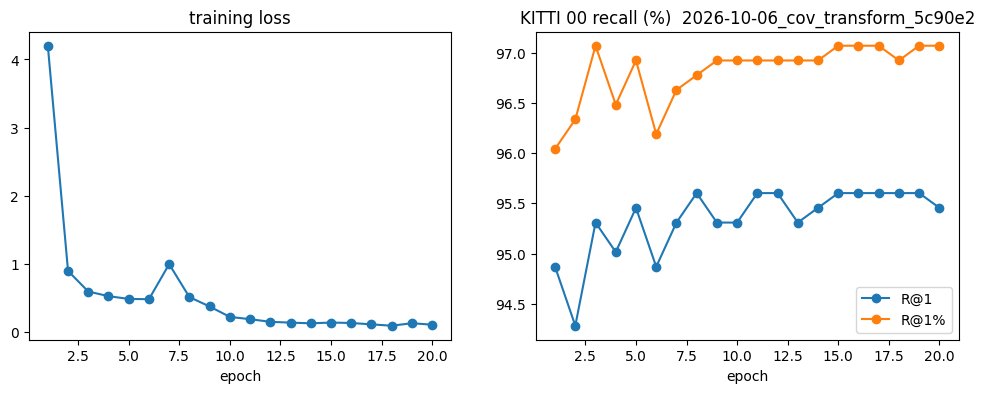

In [13]:
import pandas as pd, matplotlib.pyplot as plt
last = sorted(f for f in os.listdir(RUN_DIR) if f.startswith("epoch_"))[-1]
cmd = ["python", "scripts/eval_ndt_kitti.py", "--ckpt", f"{RUN_DIR}/{last}", "--ndt_dir", NDT,
       "--kitti_root", KITTI, "--seq", SEQ, "--out", f"{RUN_DIR}/eval_{SEQ}.json"]
res = subprocess.run(cmd, capture_output=True, text=True, cwd="/content/lpr")
print("checkpoint:", last)
print(res.stdout if res.returncode == 0 else res.stderr[-3000:])

m = pd.read_csv(f"{RUN_DIR}/metrics.csv").drop_duplicates("epoch", keep="last")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(m.epoch, m.train_loss, marker="o"); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(m.epoch, m["R@1"], marker="o", label="R@1"); ax[1].plot(m.epoch, m["R@1%"], marker="o", label="R@1%")
ax[1].set_title(f"KITTI {SEQ} recall (%)  {RUN}"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

In [14]:
!python scripts/summarize_runs.py --drive {DRIVE} > /dev/null
display(pd.read_csv(f"{DRIVE}/runs_summary.csv"))

,method,run,status,variant,gpu,started,commit,lr,epochs,negatives,...,eval_02_R@1%,eval_05_R@1,eval_05_R@1%,eval_06_R@1,eval_06_R@1%,eval_08_R@1,eval_08_R@1%,pre_voxel,pre_res,pre_max_count
0,ndt,2026-10-04_baseline_4ed638,finished,2026-10-04_baseline_717e81,Tesla T4,2026-10-04,63d57d2,0.00001,20.0,18.0,...,83.552632,89.485459,91.275168,98.518519,100.00000,4.262295,6.885246,NaN,NaN,NaN
1,ndt,2026-10-06_cov_transform_5c90e2,finished,2026-10-04_baseline_717e81,Tesla T4,2026-10-06T07:42:29,25fb722,0.00001,20.0,18.0,...,82.894737,89.932886,93.064877,98.888889,99.62963,5.245902,10.819672,NaN,NaN,NaN
2,bev,2026-10-05_baseline_4ac7d1,running,2026-10-05_baseline_7711ab,Tesla T4,2026-10-05T18:13:10,d2c8f71,0.00010,20.0,10.0,...,100.000000,98.434004,99.552573,100.000000,100.00000,91.147541,99.344262,0.4,0.4,10.0
3,bev,official_2026-10-05_baseline_7711ab,finished,2026-10-05_baseline_7711ab,NaN,NaN,NaN,NaN,NaN,NaN,...,100.000000,97.539150,98.657718,100.000000,100.00000,94.098361,99.672131,0.4,0.4,10.0


## 9. All sequences: evaluation and query headings

**9a. Cells from Azure.** The cells of 02, 05, 06 and 08 are built on the Azure VM with `scripts/azure_build.sh` (`METHOD=ndt`)
(see the README) and copied here into the variant's Drive folder. The container SAS URL is read from Colab Secrets (`AZURE_SAS`, permissions: read, list).

In [15]:
import pandas as pd
from IPython.display import Image, display
from google.colab import userdata
SAS_URL = userdata.get("AZURE_SAS")      # Colab Secrets; https://<account>.blob.core.windows.net/<container>?sv=...
EVAL_SEQS = ["00", "02", "05", "06", "08"]

missing = [s for s in EVAL_SEQS if not os.path.exists(f"{VDIR}/cells_{s}.tar")]
if missing and SAS_URL:
    res = subprocess.run(["python", "scripts/fetch_from_azure.py", "--sas_url", SAS_URL, "--method", "ndt", "--variant", VARIANT,
                          "--seqs", *missing, "--drive", DRIVE], capture_output=True, text=True, cwd="/content/lpr")
    print(res.stdout, res.stderr[-2000:])
print("cells on Drive for:", [s for s in EVAL_SEQS if os.path.exists(f"{VDIR}/cells_{s}.tar")])

cells on Drive for: ['00', '02', '05', '06', '08']


**9b. Evaluation of the run on every sequence** (last epoch, no retraining; BEVPlace++ split of each sequence).
Results: `eval_<seq>.json` and `eval_<seq>_matches.npz` in the run folder; the summary table gets a column per sequence.

In [16]:
last = sorted(f for f in os.listdir(RUN_DIR) if f.startswith("epoch_"))[-1]
results = {}
for s in EVAL_SEQS:
    tar = f"{VDIR}/cells_{s}.tar"
    if not os.path.exists(tar):
        print(f"{s}: no cells, skipped"); continue
    if not os.path.exists(f"{NDT}/{s}/000000.bin"):
        os.makedirs(NDT, exist_ok=True)
        subprocess.run(["tar", "-xf", tar, "-C", NDT], check=True)
    out = f"{RUN_DIR}/eval_{s}.json"
    # evaluate again if the saved result belongs to another checkpoint
    stale = os.path.exists(out) and os.path.basename(json.load(open(out)).get("ckpt", "")) != last
    if not os.path.exists(out) or stale:
        res = subprocess.run(["python", "scripts/eval_ndt_kitti.py", "--ckpt", f"{RUN_DIR}/{last}", "--ndt_dir", NDT,
                              "--kitti_root", KITTI, "--seq", s, "--out", out],
                             capture_output=True, text=True, cwd="/content/lpr")
        if res.returncode != 0:
            print(f"{s}: failed\n", res.stderr[-2000:]); continue
    r = json.load(open(out))
    results[s] = {k: round(r[k], 2) for k in ("R@1", "R@5", "R@1%")} | {"queries": r["n_queries_with_positive"]}
display(pd.DataFrame(results).T)

,R@1,R@5,R@1%,queries
00,95.45,95.75,97.07,682.0
02,80.59,81.58,82.89,304.0
05,89.93,91.95,93.06,447.0
06,98.89,99.63,99.63,270.0
08,5.25,6.56,10.82,305.0


**9c. Query headings.** For every query with a map frame within 5 m: heading difference to the nearest map frame,
and the smallest difference to any map frame within 5 m; grouped into same (<45°), crossing (45-135°), opposite (>135°),
with the Recall@1 of each group. Saved in `MyDrive/lpr/analysis/heading/ndt/<run>/`.

seq  queries  queries_with_positive  median_diff_nearest_deg  median_diff_min_deg  % same (<45)  R@1 same (<45)  % crossing (45-135)  R@1 crossing (45-135)  % opposite (>135)  R@1 opposite (>135)
 00     1341                    682                      1.0                  0.3          97.8            97.6                  1.5                    0.0                0.7                  0.0
 02     1061                    304                      0.5                  0.2          84.2            95.7                  0.7                    0.0               15.1                  0.0
 05     1561                    447                      0.8                  0.2          93.3            95.9                  6.7                    6.7                0.0                  NaN
 06      301                    270                      0.5                  0.2         100.0            98.9                  0.0                    NaN                0.0                  NaN
 08     2871        

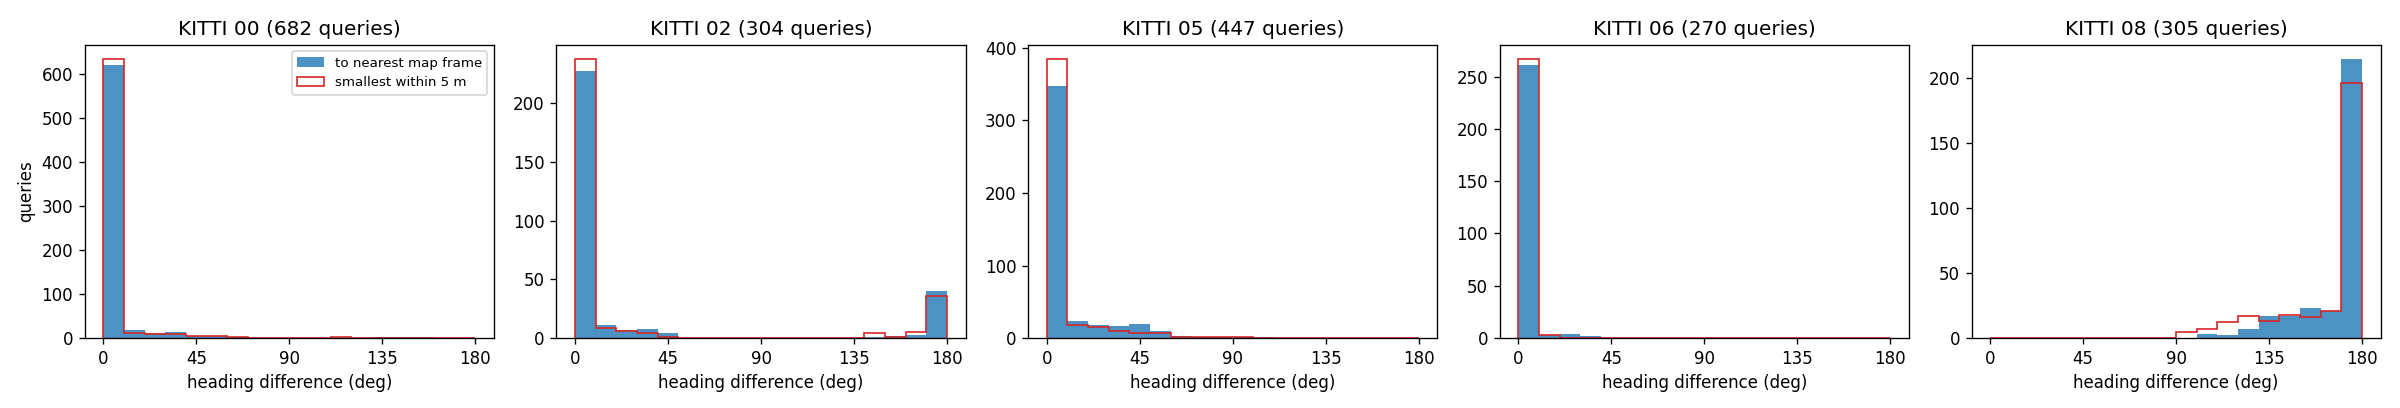

,seq,queries,queries_with_positive,median_diff_nearest_deg,median_diff_min_deg,% same (<45),R@1 same (<45),% crossing (45-135),R@1 crossing (45-135),% opposite (>135),R@1 opposite (>135)
0,0,1341,682,1.0,0.3,97.8,97.6,1.5,0.0,0.7,0.0
1,2,1061,304,0.5,0.2,84.2,95.7,0.7,0.0,15.1,0.0
2,5,1561,447,0.8,0.2,93.3,95.9,6.7,6.7,0.0,NaN
3,6,301,270,0.5,0.2,100.0,98.9,0.0,NaN,0.0,NaN
4,8,2871,305,177.2,176.1,0.0,NaN,6.6,0.0,93.4,5.6


In [17]:
HEAD_DIR = f"{DRIVE}/analysis/heading/ndt/{RUN}"
res = subprocess.run(["python", "scripts/heading_analysis.py", "--kitti_root", KITTI, "--seqs", *EVAL_SEQS,
                      "--out_dir", HEAD_DIR, "--matches_dir", RUN_DIR], capture_output=True, text=True, cwd="/content/lpr")
print(res.stdout if res.returncode == 0 else res.stderr[-2000:])
display(Image(f"{HEAD_DIR}/heading_hist.png"))
display(pd.read_csv(f"{HEAD_DIR}/heading_summary.csv"))